# 阶段二 · 数据清洗（2.1—2.5）

> 对应文档表 2 的步骤 **2.1 缺失值处置 → 2.2 类别编码 → 2.3 金额偏态处理 → 2.4 质量检查 → 2.5 保存结果**。

**输入：** `../data/audit_raw.csv`（7,000 × 59，只读不改）

**输出：** `../outputs/audit_clean.csv`（清洗后的分析用表）

**清洗的三个原则：**

1. **原始数据只读**：所有修改都在内存和输出文件里，随时能回到原始数据比对。
2. **每一步留痕**：删了哪些列、为什么删、编码后多了多少列、标准化参数是多少，全部写进 `outputs/cleaning_log.txt`。
3. **不删异常值**：这是异常检测项目，异常样本正是我们要找的对象。偏态用 `log1p` 处理，而不是删掉极端值。

**探查阶段的结论（本节的依据）：**

- 无缺失、无重复、金额全部 > 0；
- `Currency` 是常量列；
- `Abnormal_Type`、`Risk_Class` 是标签派生列，不能进特征；
- 金额和比率字段严重右偏（偏度 10.70）。

## 0. 环境与数据

先把原始数据读进来，并设置好输出目录。后面每一步都在 `df` 上操作，`df_raw` 始终保留原始数据用于对照。

In [1]:
import re
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

pd.set_option('display.max_columns', 120)
pd.set_option('display.max_rows', 120)
pd.set_option('display.max_colwidth', 60)

DATA_PATH = Path('../data/audit_raw.csv')
OUT_DIR = Path('../outputs')
FIG_DIR = OUT_DIR / 'figures'
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

RUN_TIME = datetime.now()
df_raw = pd.read_csv(DATA_PATH)

print('运行时间:', RUN_TIME.strftime('%Y-%m-%d %H:%M:%S'))
print('pandas  :', pd.__version__, '| numpy:', np.__version__, '| matplotlib:', matplotlib.__version__)
print(f'原始数据: {df_raw.shape[0]:,} 行 × {df_raw.shape[1]} 列')
print('输入文件:', DATA_PATH.resolve())

运行时间: 2026-10-18 23:00:32
pandas  : 2.3.3 | numpy: 2.3.5 | matplotlib: 3.10.6
原始数据: 7,000 行 × 59 列
输入文件: D:\ProjectFiles\VscodeProject\audit_ml_project\data\audit_raw.csv


## 2.1 缺失值统计与处置

**做法：** 先算每列缺失率，再按规则决定处置方式。规则写死在代码里，换一份数据也能复用：

| 缺失率 | 数值列 | 类别列 |
|---|---|---|
| 0 | 跳过 | 跳过 |
| 0–50% | 中位数填充 | 新增"缺失"作为一个类别 |
| > 50% | 暂不纳入 | 暂不纳入 |

**为什么：** 中位数比均值更抗极端值；类别列的"缺失"本身可能携带信息（比如"没填发票号"可能就是一种风险信号），所以不直接删行。

> 探查阶段已发现本数据 **0 缺失**，这一节的作用是留下处置表和"确实不需要处理"的证据。

In [2]:
missing_table = pd.DataFrame({
    '字段名': df_raw.columns,
    'dtype': df_raw.dtypes.astype(str).values,
    '缺失数': df_raw.isna().sum().values,
    '缺失率_%': (df_raw.isna().mean() * 100).round(2).values,
})


def decide_missing(series, rate):
    """按缺失率和列类型给出处置方式与理由。"""
    if rate == 0:
        return '跳过（无缺失）', '缺失率为 0，无需处理'
    if rate > 50:
        return '暂不纳入', '缺失率 > 50%，填充风险高'
    if pd.api.types.is_numeric_dtype(series):
        return '中位数填充', '数值列；中位数比均值更抗极端值'
    return "新增'缺失'类别", '类别列；缺失本身可能携带信息'


decisions = [
    decide_missing(df_raw[col], rate)
    for col, rate in zip(missing_table['字段名'], missing_table['缺失率_%'])
]
missing_table['处置方式'] = [d[0] for d in decisions]
missing_table['理由'] = [d[1] for d in decisions]

print('=== 缺失处置方式统计 ===')
print(missing_table['处置方式'].value_counts().to_string())
print('\n=== 缺失处置表（前 10 行）===')
display(missing_table.head(10))

missing_table.to_csv(OUT_DIR / 'missing_handling.csv', index=False, encoding='utf-8-sig')

# 真正执行处置（本数据不会触发任何分支）
df = df_raw.copy()
handled = 0
for _, row in missing_table.iterrows():
    if row['缺失率_%'] == 0:
        continue
    handled += 1
    col = row['字段名']
    if row['处置方式'] == '中位数填充':
        df[col] = df[col].fillna(df[col].median())
    elif row['处置方式'] == "新增'缺失'类别":
        df[col] = df[col].fillna('缺失')
    elif row['处置方式'] == '暂不纳入':
        df = df.drop(columns=[col])

print(f'\n实际需要处理的列数: {handled}')
assert handled == 0, '本数据本应无缺失；若触发，请检查上方处置表'
print('已保存: outputs/missing_handling.csv')

=== 缺失处置方式统计 ===
处置方式
跳过（无缺失）    59

=== 缺失处置表（前 10 行）===


,字段名,dtype,缺失数,缺失率_%,处置方式,理由
0,Transaction_ID,object,0,0.0,跳过（无缺失）,缺失率为 0，无需处理
1,Transaction_DateTime,object,0,0.0,跳过（无缺失）,缺失率为 0，无需处理
2,Fiscal_Year,int64,0,0.0,跳过（无缺失）,缺失率为 0，无需处理
3,Fiscal_Quarter,int64,0,0.0,跳过（无缺失）,缺失率为 0，无需处理
4,Month,int64,0,0.0,跳过（无缺失）,缺失率为 0，无需处理
5,Hour,int64,0,0.0,跳过（无缺失）,缺失率为 0，无需处理
6,Weekend_Flag,int64,0,0.0,跳过（无缺失）,缺失率为 0，无需处理
7,Night_Transaction_Flag,int64,0,0.0,跳过（无缺失）,缺失率为 0，无需处理
8,Source_Node_ID,object,0,0.0,跳过（无缺失）,缺失率为 0，无需处理
9,Destination_Node_ID,object,0,0.0,跳过（无缺失）,缺失率为 0，无需处理



实际需要处理的列数: 0
已保存: outputs/missing_handling.csv


**结果：0 列需要处理。** 全部 59 列缺失率都是 0，处置表原样留痕（每列都标了"跳过（无缺失）"）。

报告里可以写：*"探查发现数据无缺失，故未执行填充；处置规则仍保留在代码中以便复用。"* 这比硬套"中位数填充"更诚实，也说明方案是跟着数据走的。

## 2.2 类别编码

**做法：**

1. 先删掉不该进模型的列：
   - 常量列 `Currency`；
   - 标签派生列 `Risk_Class`（`Abnormal_Type` 保留在数据里，只用于案例分析，不进特征）；
   - 高基数标识列（节点/实体 ID、实体名称、`Invoice_ID`、节点索引）；
   - 高基数城市列（25 类，与省份重叠）。
2. 对剩余低/中基数业务类别做 **One-Hot**：
   银行 ×2、省份 ×2、账户类型 ×2、支付渠道、发票类型、边类型、审批级别。
3. 检查编码后是否还有 `object` 列。

**两个需要说明的判断：**

- **城市**：25 个取值 × 2 列 = 50 个哑变量，且信息与省份高度重叠，本项目暂不纳入。
- **省份**：12 个取值，超过文档"≤10"的阈值，但每类样本量都在 495 以上，One-Hot 只增加 24 列，信息价值高，因此保留。这是一个有意识的放宽，不是遗漏。

In [3]:
# 每一列为什么删，逐条记录
DROP_REASONS = {
    'Currency': '常量列：只有 CNY 一个取值，零信息',
    'Risk_Class': '标签派生列：与 Abnormal_Label 完全对应，特征泄漏',
    'Source_Node_ID': '高基数网络节点标识（1,490 个取值），不可泛化',
    'Destination_Node_ID': '高基数网络节点标识（1,484 个取值），不可泛化',
    'Source_Node_Index': '节点索引编号，不是业务特征',
    'Destination_Node_Index': '节点索引编号，不是业务特征',
    'Source_Entity_ID': '实体标识（586 个取值），不可泛化',
    'Destination_Entity_ID': '实体标识（586 个取值），不可泛化',
    'Source_Entity_Name': '实体名称标识（132 个取值），与实体 ID 重复',
    'Destination_Entity_Name': '实体名称标识（132 个取值），与实体 ID 重复',
    'Invoice_ID': '高基数标识（6,695 个取值）；重复发票信号已由 Duplicate_Invoice_Flag 表示',
    'Source_City': '高基数类别（25 个取值），与省份信息重叠，暂不纳入',
    'Destination_City': '高基数类别（25 个取值），与省份信息重叠，暂不纳入',
}

# 这些列保留在数据里，但不作为模型特征
KEEP_NON_FEATURE = ['Transaction_ID', 'Transaction_DateTime', 'Abnormal_Label', 'Abnormal_Type']

assert set(DROP_REASONS) <= set(df.columns), '待删列中有不存在的字段'
assert set(KEEP_NON_FEATURE) <= set(df.columns), '保留列中有不存在的字段'

drop_table = pd.DataFrame({
    '字段名': list(DROP_REASONS),
    '删除原因': list(DROP_REASONS.values()),
})
print('=== 删除列清单 ===')
display(drop_table)
drop_table.to_csv(OUT_DIR / 'dropped_columns.csv', index=False, encoding='utf-8-sig')

df = df.drop(columns=list(DROP_REASONS))
print(f'删除 {len(DROP_REASONS)} 列后: {df.shape[0]:,} 行 × {df.shape[1]} 列')

=== 删除列清单 ===


,字段名,删除原因
0,Currency,常量列：只有 CNY 一个取值，零信息
1,Risk_Class,标签派生列：与 Abnormal_Label 完全对应，特征泄漏
2,Source_Node_ID,"高基数网络节点标识（1,490 个取值），不可泛化"
3,Destination_Node_ID,"高基数网络节点标识（1,484 个取值），不可泛化"
4,Source_Node_Index,节点索引编号，不是业务特征
5,Destination_Node_Index,节点索引编号，不是业务特征
6,Source_Entity_ID,实体标识（586 个取值），不可泛化
7,Destination_Entity_ID,实体标识（586 个取值），不可泛化
8,Source_Entity_Name,实体名称标识（132 个取值），与实体 ID 重复
9,Destination_Entity_Name,实体名称标识（132 个取值），与实体 ID 重复


删除 13 列后: 7,000 行 × 46 列


In [4]:
ONEHOT_COLS = [
    'Source_Bank', 'Destination_Bank',
    'Source_Province', 'Destination_Province',
    'Source_Account_Type', 'Destination_Account_Type',
    'Payment_Channel', 'Invoice_Type', 'Edge_Type', 'Approval_Level',
]
assert set(ONEHOT_COLS) <= set(df.columns), 'One-Hot 列表中有不存在的字段'


def sanitize_name(name):
    """把类别值里的空格和特殊字符换成下划线，得到合法列名。"""
    return re.sub(r'[^0-9A-Za-z]+', '_', str(name)).strip('_')


encoded_parts = []
dummy_source = {}     # 哑变量名 -> 源字段
dummy_names = set()   # 用于去重
encoding_rows = []

for col in ONEHOT_COLS:
    dummies = pd.get_dummies(df[[col]], columns=[col], prefix=col, dtype=int)
    new_names = []
    for orig in dummies.columns:
        base = sanitize_name(orig)
        name = base
        k = 2
        while name in dummy_names:      # 极少数情况下清洗后重名，加后缀
            name = f'{base}_{k}'
            k += 1
        dummy_names.add(name)
        dummy_source[name] = col
        new_names.append(name)
    dummies.columns = new_names
    encoded_parts.append(dummies)
    encoding_rows.append({
        '源字段': col,
        '源类别数': df[col].nunique(),
        '生成哑变量数': len(new_names),
        '哑变量示例': ', '.join(new_names[:3]),
    })

# 非 One-Hot 列 + 所有哑变量
df = pd.concat([df.drop(columns=ONEHOT_COLS)] + encoded_parts, axis=1)

encoding_table = pd.DataFrame(encoding_rows)
print('=== One-Hot 编码明细 ===')
display(encoding_table)
encoding_table.to_csv(OUT_DIR / 'encoding_summary.csv', index=False, encoding='utf-8-sig')

print(f'One-Hot: {len(ONEHOT_COLS)} 个源字段 -> {len(dummy_names)} 个哑变量')
print(f'编码后总列数: {df.shape[1]}')
print('剩余 object 列:', df.select_dtypes(include='object').columns.tolist())

=== One-Hot 编码明细 ===


,源字段,源类别数,生成哑变量数,哑变量示例
0,Source_Bank,9,9,"Source_Bank_Agricultural_Bank_of_China, Source_Bank_Bank..."
1,Destination_Bank,9,9,"Destination_Bank_Agricultural_Bank_of_China, Destination..."
2,Source_Province,12,12,"Source_Province_Beijing, Source_Province_Chongqing, Sour..."
3,Destination_Province,12,12,"Destination_Province_Beijing, Destination_Province_Chong..."
4,Source_Account_Type,6,6,"Source_Account_Type_Corporate_Operating_Account, Source_..."
5,Destination_Account_Type,6,6,"Destination_Account_Type_Corporate_Operating_Account, De..."
6,Payment_Channel,7,7,"Payment_Channel_Alipay_Business, Payment_Channel_Branch_..."
7,Invoice_Type,6,6,"Invoice_Type_Customs_Invoice, Invoice_Type_Electronic_In..."
8,Edge_Type,8,8,"Edge_Type_Asset_Purchase, Edge_Type_Customer_Receipt, Ed..."
9,Approval_Level,4,4,"Approval_Level_Audit_Required, Approval_Level_Auto_Appro..."


One-Hot: 10 个源字段 -> 79 个哑变量
编码后总列数: 115
剩余 object 列: ['Transaction_ID', 'Transaction_DateTime', 'Abnormal_Type']


**结果：**

- 删除 13 列（1 常量 + 1 泄漏 + 9 标识/索引 + 2 城市），59 → 46 列；
- 10 个类别字段 One-Hot 成 79 个哑变量，46 → **115 列**；
- 编码后只剩 `Transaction_ID`、`Transaction_DateTime`、`Abnormal_Label`、`Abnormal_Type` 四个 object 列，它们都不是特征：
  - 前两列是标识/时间，供后续 join 和筛选；
  - 后两列是标签，只用于评估和案例归因。

## 2.3 金额偏态处理：log1p + z-score

**做什么：** 对 4 个金额/比率字段做 `log1p`，再做 z-score 标准化：

`Transaction_Amount_RMB`、`Historical_Avg_Amount_RMB`、`Transaction_to_Avg_Ratio`、`Amount_Threshold_Ratio`

**为什么：**

- `log1p(x) = log(1 + x)`：压缩长尾，且 x = 0 时结果仍为 0，适合非负字段；
- z-score：`(x − mean) / std`，把不同量纲拉到同一尺度；
- **不删除极端值**：在异常检测任务里，极端值很可能就是异常样本本身，删掉等于把要抓的目标扔掉。

**关于标准化范围：** 本项目是无监督、单数据集分析，没有 train/test 划分，所以 scaler 在全部 7,000 条上 fit，不涉及标签泄漏。如果以后要划分训练集/测试集，scaler 只能在训练集上 fit。

只变换这 4 列，其他数值字段保留原尺度，便于解释。

In [5]:
LOG_COLS = [
    'Transaction_Amount_RMB',
    'Historical_Avg_Amount_RMB',
    'Transaction_to_Avg_Ratio',
    'Amount_Threshold_Ratio',
]
assert set(LOG_COLS) <= set(df.columns), '待变换列中有不存在的字段'

before_stats = df[LOG_COLS].agg(['min', 'median', 'max', 'skew']).T.round(3)
print('=== 变换前 ===')
display(before_stats)

# 第一步：log1p（先压长尾）
assert (df[LOG_COLS] >= 0).all().all(), 'log1p 要求字段非负'
log_values = np.log1p(df[LOG_COLS])

# 第二步：在 log 空间做 z-score
scaler = StandardScaler()
scaled_values = scaler.fit_transform(log_values)

for i, col in enumerate(LOG_COLS):
    df[col + '_log_z'] = scaled_values[:, i]
df = df.drop(columns=LOG_COLS)

scaler_table = pd.DataFrame({
    '源字段': LOG_COLS,
    '新字段': [c + '_log_z' for c in LOG_COLS],
    'mean(log1p)': scaler.mean_.round(6),
    'std(log1p)': scaler.scale_.round(6),
})
print('\n=== 标准化参数 ===')
display(scaler_table)
scaler_table.to_csv(OUT_DIR / 'scaler_params.csv', index=False, encoding='utf-8-sig')

after_stats = df[[c + '_log_z' for c in LOG_COLS]].agg(['min', 'median', 'max', 'skew']).T.round(3)
print('=== 变换后 ===')
display(after_stats)
print(f'总列数: {df.shape[1]}（列数不变，4 列被替换为 *_log_z）')

=== 变换前 ===


,min,median,max,skew
Transaction_Amount_RMB,890.630,23063.125,3181864.090,10.700
Historical_Avg_Amount_RMB,1482.930,21778.990,565344.500,3.693
Transaction_to_Avg_Ratio,0.123,1.017,164.789,12.481
Amount_Threshold_Ratio,0.003,0.212,63.637,16.101



=== 标准化参数 ===


,源字段,新字段,mean(log1p),std(log1p)
0,Transaction_Amount_RMB,Transaction_Amount_RMB_log_z,10.095950,1.073424
1,Historical_Avg_Amount_RMB,Historical_Avg_Amount_RMB_log_z,9.990106,0.754570
2,Transaction_to_Avg_Ratio,Transaction_to_Avg_Ratio_log_z,0.812646,0.529145
3,Amount_Threshold_Ratio,Amount_Threshold_Ratio_log_z,0.315356,0.374022


=== 变换后 ===


,min,median,max,skew
Transaction_Amount_RMB_log_z,-3.077,-0.047,4.543,0.523
Historical_Avg_Amount_RMB_log_z,-3.562,-0.002,4.314,-0.001
Transaction_to_Avg_Ratio_log_z,-1.317,-0.210,8.123,3.531
Amount_Threshold_Ratio_log_z,-0.836,-0.329,10.303,3.132


总列数: 115（列数不变，4 列被替换为 *_log_z）


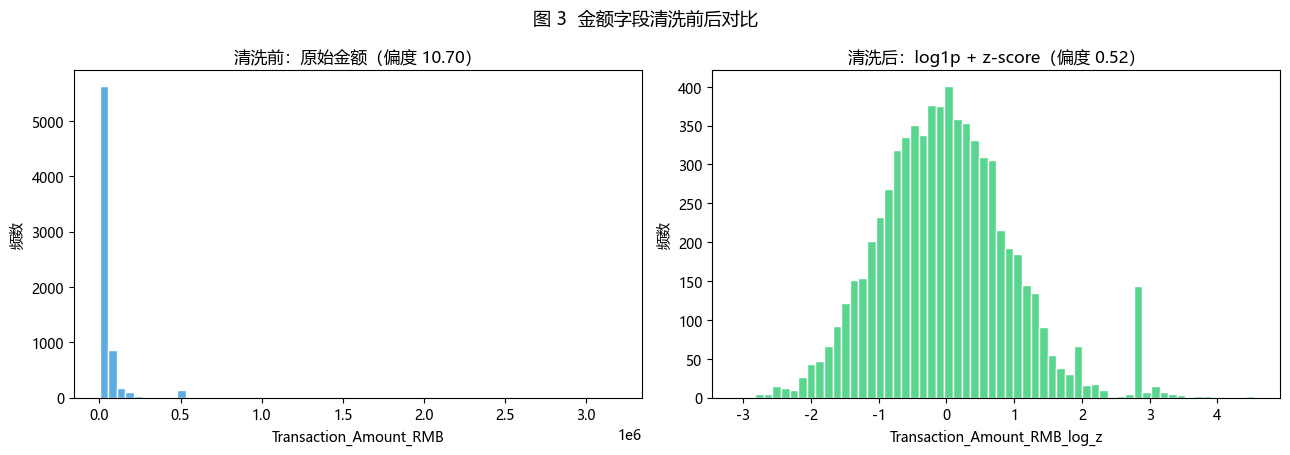

已保存: outputs/figures/03_amount_transform_compare.png


In [6]:
# 变换前后分布对比图
raw_amount = df_raw['Transaction_Amount_RMB']
final_amount = df['Transaction_Amount_RMB_log_z']

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

axes[0].hist(raw_amount, bins=60, color='#5DADE2', edgecolor='white')
axes[0].set_title(f'清洗前：原始金额（偏度 {raw_amount.skew():.2f}）')
axes[0].set_xlabel('Transaction_Amount_RMB')
axes[0].set_ylabel('频数')

axes[1].hist(final_amount, bins=60, color='#58D68D', edgecolor='white')
axes[1].set_title(f'清洗后：log1p + z-score（偏度 {final_amount.skew():.2f}）')
axes[1].set_xlabel('Transaction_Amount_RMB_log_z')
axes[1].set_ylabel('频数')

fig.suptitle('图 3  金额字段清洗前后对比', fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / '03_amount_transform_compare.png', dpi=150, bbox_inches='tight')
plt.show()
print('已保存: outputs/figures/03_amount_transform_compare.png')

**结果：**

- 原始金额偏度 **10.70** → `log1p` 后 **0.52** → z-score 后仍为 **0.52**（线性变换不改变偏度），长尾被明显压缩；
- `Historical_Avg_Amount_RMB`：3.69 → 0.00；两个比率字段：12.48 → 3.53、16.10 → 3.13——改善很大，但比率本身存在极端离群，仍未完全对称。这是有意的保留：异常检测项目不删极端值；
- 变换后 4 个字段的均值约为 0、标准差为 1；
- 具体参数已保存到 `scaler_params.csv`（`mean(log1p)` / `std(log1p)`，注意是 log 空间的均值和标准差）。需要还原原始金额时：`x = expm1(z * std + mean)`。

> 注意：`Approval_Threshold_RMB` 是离散阈值（5 万/10 万/20 万/50 万），保留原值，不做 log；其他长尾计数类字段（如 `Common_Counterparty_Count`）也先保留原值。文档只要求处理金额，先按最小改动原则来。

## 2.4 质量检查（清洗后）

**做什么：** 把探查阶段的检查再跑一遍，并额外检查建模矩阵：

1. 行数不变、交易 ID 仍唯一；
2. 标签分布与清洗前完全一致；
3. 特征矩阵无缺失、无 NaN/Inf；
4. 所有特征都是数值型、列名不重复。

**为什么：** 清洗最怕"悄悄改坏了数据"。清洗前后各留一份检查表，就能证明变化都在预期之内。

In [7]:
feature_cols = [c for c in df.columns if c not in KEEP_NON_FEATURE]
print(f'特征列数: {len(feature_cols)}')
print(f'非特征列: {KEEP_NON_FEATURE}')

checks = []


def add_check(name, passed, detail):
    checks.append({
        '检查项': name,
        '结果': '通过' if passed else '发现问题',
        '详情': detail,
    })


# 行与标识
add_check('行数保持 7,000', len(df) == len(df_raw), f'{len(df):,} 行')
add_check('交易 ID 唯一', df['Transaction_ID'].duplicated().sum() == 0,
          f'重复 {int(df["Transaction_ID"].duplicated().sum())} 条')
add_check('交易 ID 与原始顺序一致', df['Transaction_ID'].equals(df_raw['Transaction_ID']), '逐行比对')

# 标签
label_same = df['Abnormal_Label'].value_counts().sort_index().equals(
    df_raw['Abnormal_Label'].value_counts().sort_index())
add_check('标签分布不变', label_same,
          f'异常 {(df["Abnormal_Label"] == 1).sum()} 条')

# 特征矩阵
add_check('无缺失值', df.isna().sum().sum() == 0, f'缺失 {int(df.isna().sum().sum())} 个')
values = df[feature_cols].to_numpy(dtype=float)
add_check('无 NaN / Inf', bool(np.isfinite(values).all()), 'np.isfinite 全量检查')
add_check('特征全部为数值型',
          all(pd.api.types.is_numeric_dtype(df[c]) for c in feature_cols),
          f'{len(feature_cols)} 列')
add_check('特征列名无重复', len(feature_cols) == len(set(feature_cols)),
          f'{len(set(feature_cols))} 个唯一列名')

# 原始业务约束
add_check('原始金额全部 > 0', bool((df_raw['Transaction_Amount_RMB'] > 0).all()),
          f'最小值 {df_raw["Transaction_Amount_RMB"].min():,.2f}')

after_quality = pd.DataFrame(checks)
print('\n=== 清洗后质量检查 ===')
display(after_quality)
after_quality.to_csv(OUT_DIR / 'quality_check_after_clean.csv', index=False, encoding='utf-8-sig')

# 和清洗前的检查表并排对照
before_quality = pd.read_csv(OUT_DIR / 'quality_check_before_clean.csv', encoding='utf-8-sig')
compare = before_quality[['检查项', '结果']].rename(columns={'结果': '清洗前'}).merge(
    after_quality[['检查项', '结果']].rename(columns={'结果': '清洗后'}),
    on='检查项', how='outer')
print('\n=== 清洗前后检查对照 ===')
display(compare)
compare.to_csv(OUT_DIR / 'quality_check_compare.csv', index=False, encoding='utf-8-sig')

assert (after_quality['结果'] == '通过').all(), '存在未通过的质量检查，请先处理'
print('全部检查通过 ✓')

特征列数: 111
非特征列: ['Transaction_ID', 'Transaction_DateTime', 'Abnormal_Label', 'Abnormal_Type']

=== 清洗后质量检查 ===


,检查项,结果,详情
0,"行数保持 7,000",通过,"7,000 行"
1,交易 ID 唯一,通过,重复 0 条
2,交易 ID 与原始顺序一致,通过,逐行比对
3,标签分布不变,通过,异常 955 条
4,无缺失值,通过,缺失 0 个
5,无 NaN / Inf,通过,np.isfinite 全量检查
6,特征全部为数值型,通过,111 列
7,特征列名无重复,通过,111 个唯一列名
8,原始金额全部 > 0,通过,最小值 890.63



=== 清洗前后检查对照 ===


,检查项,清洗前,清洗后
0,交易 ID 与原始顺序一致,NaN,通过
1,交易 ID 唯一,通过,通过
2,原始金额全部 > 0,NaN,通过
3,无 NaN / Inf,NaN,通过
4,无整行重复,通过,NaN
5,无缺失值,NaN,通过
6,时间戳可解析,通过,NaN
7,时间范围合理,通过,NaN
8,标签分布不变,NaN,通过
9,标签只含 0/1,通过,NaN


全部检查通过 ✓


**结果：全部通过。**

- 行数 **7,000 → 7,000**，删除 0 行；
- 标签分布不变（异常 955 条）；
- 111 个特征列全部为数值型，无缺失、无 NaN/Inf、无重名列；
- 原始金额约束仍然成立。

清洗前后的检查表已并排保存为 `quality_check_compare.csv`，可以直接放进汇报附录。

## 2.5 保存清洗结果与清洗日志

**输出文件说明：**

| 文件 | 内容 |
|---|---|
| `audit_clean.csv` | 清洗后的分析用表：标识 2 列 + 特征 111 列 + 标签 2 列 |
| `clean_feature_columns.csv` | 111 个特征的清单：类型、变换方式、来源字段 |
| `dimension_change.csv` | 每一步的行列数变化 |
| `cleaning_log.txt` | 文字版清洗日志（可直接贴进报告） |
| `missing_handling.csv` | 2.1 缺失处置表 |
| `dropped_columns.csv` | 2.2 删除列及原因 |
| `encoding_summary.csv` | 2.2 One-Hot 明细 |
| `scaler_params.csv` | 2.3 标准化参数 |
| `quality_check_after_clean.csv` / `quality_check_compare.csv` | 2.4 质量检查与前后对照 |

> **重要：** `audit_clean.csv` 里保留了 `Abnormal_Label` 和 `Abnormal_Type` 用于评估，它们**不是特征**。下一阶段训练模型时，只读 `clean_feature_columns.csv` 里列出的 111 列。

In [8]:
# 时间戳转成标准 datetime，方便后续按时间筛选
df['Transaction_DateTime'] = pd.to_datetime(df['Transaction_DateTime'])

# 列顺序：标识 -> 特征 -> 标签
ordered_cols = ['Transaction_ID', 'Transaction_DateTime'] + feature_cols + ['Abnormal_Label', 'Abnormal_Type']
df_clean = df[ordered_cols].copy()

assert df_clean.shape == (7000, 115), f'预期 (7000, 115)，实际 {df_clean.shape}'
assert df_clean[feature_cols].isna().sum().sum() == 0

df_clean.to_csv(OUT_DIR / 'audit_clean.csv', index=False, encoding='utf-8-sig')

# 特征清单
feature_info = []
for c in feature_cols:
    if c in dummy_source:
        ftype, transform, source = 'one-hot', 'One-Hot 编码', dummy_source[c]
    elif c.endswith('_log_z'):
        ftype, transform, source = 'amount', 'log1p + z-score', c[:-6]
    else:
        ftype, transform, source = 'numeric', '保持原值', c
    feature_info.append({
        '特征名': c,
        '特征类型': ftype,
        '变换方式': transform,
        '来源字段': source,
    })

feature_table = pd.DataFrame(feature_info)
feature_table.to_csv(OUT_DIR / 'clean_feature_columns.csv', index=False, encoding='utf-8-sig')
print('=== 特征类型统计 ===')
display(feature_table['特征类型'].value_counts().to_frame('数量'))
print(f'特征总数: {len(feature_table)}')

=== 特征类型统计 ===


,数量
特征类型,
one-hot,79
numeric,28
amount,4


特征总数: 111


In [9]:
# 行列数变化记录
dimension_table = pd.DataFrame([
    {'阶段': '原始数据', '操作': '读取 audit_raw.csv', '行数': df_raw.shape[0], '列数': df_raw.shape[1]},
    {'阶段': '2.1 缺失处置', '操作': '0 列需要处理（数据无缺失）', '行数': 7000, '列数': 59},
    {'阶段': '2.2 删除列', '操作': f'删除 {len(DROP_REASONS)} 列（常量/泄漏/标识/城市）', '行数': 7000, '列数': 46},
    {'阶段': '2.2 One-Hot', '操作': f'{len(ONEHOT_COLS)} 列 -> {len(dummy_names)} 列哑变量', '行数': 7000, '列数': 115},
    {'阶段': '2.3 log1p+zscore', '操作': '4 列替换为 *_log_z（列数不变）', '行数': 7000, '列数': 115},
    {'阶段': '最终', '操作': '导出 audit_clean.csv', '行数': df_clean.shape[0], '列数': df_clean.shape[1]},
])
print('=== 行列数变化 ===')
display(dimension_table)
dimension_table.to_csv(OUT_DIR / 'dimension_change.csv', index=False, encoding='utf-8-sig')

=== 行列数变化 ===


,阶段,操作,行数,列数
0,原始数据,读取 audit_raw.csv,7000,59
1,2.1 缺失处置,0 列需要处理（数据无缺失）,7000,59
2,2.2 删除列,删除 13 列（常量/泄漏/标识/城市）,7000,46
3,2.2 One-Hot,10 列 -> 79 列哑变量,7000,115
4,2.3 log1p+zscore,4 列替换为 *_log_z（列数不变）,7000,115
5,最终,导出 audit_clean.csv,7000,115


In [10]:
# 保存文字版清洗日志
log_lines = [
    '智慧审计数据集 · 清洗日志',
    f'生成时间: {RUN_TIME:%Y-%m-%d %H:%M:%S}',
    f'输入文件: {DATA_PATH.resolve()}',
    f'输出文件: {(OUT_DIR / "audit_clean.csv").resolve()}',
    '',
    f'行数: {df_raw.shape[0]} -> {df_clean.shape[0]}（删除 0 行）',
    f'列数: {df_raw.shape[1]} -> {df_clean.shape[1]}',
    f'特征列: {len(feature_cols)} | 非特征列(标识/标签): {len(KEEP_NON_FEATURE)}',
    '',
    '2.1 缺失值:',
    '  全部 59 列缺失率为 0，未执行填充；处置规则保留在代码中以便复用。',
    '',
    '2.2 删除列（13 列）:',
]
for col, reason in DROP_REASONS.items():
    log_lines.append(f'  - {col}: {reason}')

log_lines += [
    '',
    f'2.2 One-Hot: {len(ONEHOT_COLS)} 个源字段 -> {len(dummy_names)} 个哑变量',
]
for row in encoding_rows:
    log_lines.append(f"  - {row['源字段']}: {row['源类别数']} 类 -> {row['生成哑变量数']} 列")

log_lines += [
    '',
    '2.3 金额变换（log1p + z-score）:',
]
for _, row in scaler_table.iterrows():
    log_lines.append(
        f"  - {row['源字段']} -> {row['新字段']}: mean(log1p)={row['mean(log1p)']}, std(log1p)={row['std(log1p)']}"
    )

log_lines += [
    '',
    '2.4 质量检查:',
]
for row in checks:
    log_lines.append(f"  - {row['检查项']}: {row['结果']}（{row['详情']}）")

log_lines += [
    '',
    '说明:',
    '  - 未删除任何异常值（异常样本是检测目标）。',
    '  - 未使用标签信息参与特征构造或标准化；标签仅用于后续评估。',
    '  - 城市字段暂不纳入（25 类，与省份重叠）；省份 12 类予以 One-Hot（有意识的放宽）。',
]
(OUT_DIR / 'cleaning_log.txt').write_text('\n'.join(log_lines), encoding='utf-8')
print('已保存: outputs/cleaning_log.txt\n')
print('\n'.join(log_lines))

已保存: outputs/cleaning_log.txt

智慧审计数据集 · 清洗日志
生成时间: 2026-10-18 23:00:32
输入文件: D:\ProjectFiles\VscodeProject\audit_ml_project\data\audit_raw.csv
输出文件: D:\ProjectFiles\VscodeProject\audit_ml_project\outputs\audit_clean.csv

行数: 7000 -> 7000（删除 0 行）
列数: 59 -> 115
特征列: 111 | 非特征列(标识/标签): 4

2.1 缺失值:
  全部 59 列缺失率为 0，未执行填充；处置规则保留在代码中以便复用。

2.2 删除列（13 列）:
  - Currency: 常量列：只有 CNY 一个取值，零信息
  - Risk_Class: 标签派生列：与 Abnormal_Label 完全对应，特征泄漏
  - Source_Node_ID: 高基数网络节点标识（1,490 个取值），不可泛化
  - Destination_Node_ID: 高基数网络节点标识（1,484 个取值），不可泛化
  - Source_Node_Index: 节点索引编号，不是业务特征
  - Destination_Node_Index: 节点索引编号，不是业务特征
  - Source_Entity_ID: 实体标识（586 个取值），不可泛化
  - Destination_Entity_ID: 实体标识（586 个取值），不可泛化
  - Source_Entity_Name: 实体名称标识（132 个取值），与实体 ID 重复
  - Destination_Entity_Name: 实体名称标识（132 个取值），与实体 ID 重复
  - Invoice_ID: 高基数标识（6,695 个取值）；重复发票信号已由 Duplicate_Invoice_Flag 表示
  - Source_City: 高基数类别（25 个取值），与省份信息重叠，暂不纳入
  - Destination_City: 高基数类别（25 个取值），与省份信息重叠，暂不纳入

2.2 One-Hot: 10 个源字段 -> 79 个哑变量
  - 

In [11]:
# 重新读回 audit_clean.csv，确认落盘文件没问题
clean_check = pd.read_csv(OUT_DIR / 'audit_clean.csv', encoding='utf-8-sig')

print('=== 落盘文件复核 ===')
print('形状      :', clean_check.shape)
print('dtype 分布:')
print(clean_check.dtypes.value_counts().to_string())
print('缺失值总数:', int(clean_check.isna().sum().sum()))
print('Transaction_ID 与原始一致:', clean_check['Transaction_ID'].equals(df_raw['Transaction_ID']))
print('标签与原始一致:', bool((clean_check['Abnormal_Label'] == df_raw['Abnormal_Label']).all()))
print('\n标签分布:')
print(clean_check['Abnormal_Label'].value_counts().sort_index().to_string())

print('\n本次清洗生成的文件：')
for name in [
    'audit_clean.csv', 'clean_feature_columns.csv', 'dimension_change.csv',
    'cleaning_log.txt', 'missing_handling.csv', 'dropped_columns.csv',
    'encoding_summary.csv', 'scaler_params.csv',
    'quality_check_after_clean.csv', 'quality_check_compare.csv',
    'figures/03_amount_transform_compare.png',
]:
    p = OUT_DIR / name
    print(f'  {p.as_posix():50s} {p.stat().st_size / 1024:8.1f} KB')

=== 落盘文件复核 ===
形状      : (7000, 115)
dtype 分布:
int64      99
float64    13
object      3
缺失值总数: 0
Transaction_ID 与原始一致: True
标签与原始一致: True

标签分布:
Abnormal_Label
0    6045
1     955

本次清洗生成的文件：
  ../outputs/audit_clean.csv                           2754.1 KB
  ../outputs/clean_feature_columns.csv                    7.8 KB
  ../outputs/dimension_change.csv                         0.4 KB
  ../outputs/cleaning_log.txt                             3.2 KB
  ../outputs/missing_handling.csv                         4.9 KB
  ../outputs/dropped_columns.csv                          1.0 KB
  ../outputs/encoding_summary.csv                         1.3 KB
  ../outputs/scaler_params.csv                            0.3 KB
  ../outputs/quality_check_after_clean.csv                0.4 KB
  ../outputs/quality_check_compare.csv                    0.5 KB
  ../outputs/figures/03_amount_transform_compare.png     65.1 KB


## 清洗总结

| 指标 | 清洗前 | 清洗后 |
|---|---|---|
| 行数 | 7,000 | 7,000（删除 0 行） |
| 列数 | 59 | 115 |
| 特征数 | — | 111 |
| 缺失值 | 0 | 0 |
| 异常样本 | 955（13.64%） | 955（13.64%） |
| 金额偏度 | 10.70 | 0.52（log1p 后） |

**115 列的构成：**

- 标识 2 列：`Transaction_ID`、`Transaction_DateTime`
- 特征 111 列：79 个 One-Hot + 28 个原始数值 + 4 个 `*_log_z`
- 标签 2 列：`Abnormal_Label`（目标）、`Abnormal_Type`（案例分析）

**下一阶段（文档 3.1—3.5 分析）：** 建立 `03_analysis.ipynb`：

1. Benford 首位数字基线 + MAD；
2. Isolation Forest（`contamination=0.02`）异常打分；
3. Top-K 召回评估（K = 50 / 100 / 140）+ K–召回曲线；
4. Benford × 模型 2×2 交叉表；
5. 从"仅模型标记"里挑 2—3 条做人工归因。

进入分析阶段后，**只读 `clean_feature_columns.csv` 中的 111 个特征**，不要碰 `Abnormal_Label` / `Abnormal_Type`。